In [2]:
# Block 0 — setup. Code from GitHub onto the VM disk; data + embeddings on Drive.
import os, sys
from google.colab import drive
drive.mount('/content/drive')

REPO_DIR = "/content/NeoAntigen"
try:   # private repo: store a GitHub token as Colab secret GH_TOKEN
    from google.colab import userdata
    TOKEN = userdata.get("GH_TOKEN")
except Exception:
    TOKEN = ""
URL = f"https://{TOKEN + '@' if TOKEN else ''}github.com/Tienanh209/NeoAntigen.git"
if not os.path.exists(REPO_DIR):
    !git clone {URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull --ff-only
%cd {REPO_DIR}
sys.path.insert(0, REPO_DIR)

# numpy/scipy/torch are filtered out: Colab's torch is built against its own numpy
!grep -viE '^(torch|torchvision|torchaudio|nvidia-|numpy|scipy|#)' requirements.txt > req_colab.txt
!pip install -q -r req_colab.txt

Mounted at /content/drive
Cloning into '/content/NeoAntigen'...
remote: Enumerating objects: 62, done.
remote: Counting objects: 100% (62/62), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 62 (delta 27), reused 57 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (62/62), 686.16 KiB | 2.82 MiB/s, done.
Resolving deltas: 100% (27/27), done.
/content/NeoAntigen


In [3]:
# Block 1 — dataset, embedding caches, shared settings.
# Every experiment block below depends on THIS cell and on nothing else:
# they communicate only through the results store on Drive.
import pandas as pd
from src import config, data, embed, results, runner

df = data.load_dataset()
BID = data.build_id(df)
MAXLEN = data.max_len(df)
SEEDS = (42,)               # single seed: fast, but AUC_std is then NaN and nothing
                            # separates a real effect from run-to-run noise
PLM = "prott5"              # feature set for the hyperparameter sweeps, as in the paper
ESM = "esm2_650m"           # the ESM model used by the ESM baselines
FORCE = False               # True re-runs committed configurations

for plm in ("prott5", "esm2_650m", "esm1b"):
    if embed.is_cached(plm, BID):
        embed.stage(plm, BID)
    else:
        print(f"!! {plm} has no cache for build {BID} — run embeddings.ipynb (CEDAR) or embeddings_authors.ipynb (authors) first")

print("build id:", BID, "| max_len:", MAXLEN, "| results:", config.RESULTS_DIR)
print(df.groupby(["split", "label"]).size().unstack(fill_value=0))

[prott5] staged to /content/work/emb_staged/e2a2999ece/prott5
[esm2_650m] staged to /content/work/emb_staged/e2a2999ece/esm2_650m
[esm1b] staged to /content/work/emb_staged/e2a2999ece/esm1b
build id: e2a2999ece | max_len: 35 | results: /content/drive/MyDrive/s1156052/NeoAntigen/ckpt/results
label     0    1
split           
test    334   25
train  1332  102


[A_window 1/5] window 8
  [skip] window 8 — already committed
[A_window 2/5] window 16
  [skip] window 16 — already committed
[A_window 3/5] window 24
  [skip] window 24 — already committed
[A_window 4/5] window 32
  [skip] window 32 — already committed
[A_window 5/5] window 34
  [skip] window 34 — already committed

Independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,window 8,0.60,0.6557,0.6518,0.1354,0.6874,0.1232,0.1935,0.1154,0.6874,NaN
1,window 16,0.12,0.9461,0.8886,0.0717,0.7228,0.1443,0.1304,0.1429,0.7228,NaN
2,window 24,0.20,0.9521,0.8997,0.1650,0.7323,0.1906,0.2174,0.2381,0.7323,NaN
3,window 32,0.52,0.9701,0.9387,0.5094,0.8891,0.5313,0.5417,0.5652,0.8891,NaN
4,window 34,0.76,0.9192,0.9081,0.5172,0.8953,0.5032,0.5352,0.4130,0.8953,NaN
5,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


5-fold cross-validation


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,window 8,0.5392,0.6517,0.6437,0.1021,0.6036,0.1073,0.1771,0.1060,0.6036,NaN
1,window 16,0.2059,0.9542,0.9010,0.1772,0.6002,0.1334,0.2283,0.2561,0.6002,NaN
2,window 24,0.2549,0.9557,0.9059,0.2293,0.7412,0.2181,0.2781,0.3059,0.7412,NaN
3,window 32,0.4706,0.9677,0.9324,0.4621,0.8762,0.4052,0.4974,0.5275,0.8762,NaN
4,window 34,0.7353,0.9174,0.9045,0.5005,0.8742,0.4010,0.5226,0.4054,0.8742,NaN
5,all-negative baseline,0.0000,1.0000,0.9289,0.0000,0.5000,0.0711,0.0000,0.0000,NaN,NaN


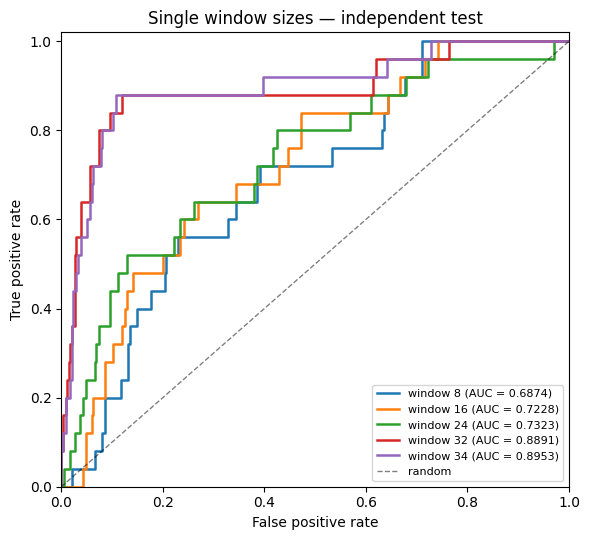

In [4]:
# Block 2 — Experiment A: single window sizes (paper Table 2)
cfgs = [dict(label=f"window {w}", features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": [w], "filters": 512})
        for w in (8, 16, 24, 32, 34)]
runner.run_series("A_window", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("\nIndependent test")
display(results.fmt(results.table("A_window")))
print("5-fold cross-validation")
display(results.fmt(results.table("A_window", eval_split="cv")))
results.roc("A_window", title="Single window sizes — independent test");

[B_combo 1/5] [34]
  [skip] [34] — already committed
[B_combo 2/5] [34, 32]
  [skip] [34, 32] — already committed
[B_combo 3/5] [34, 32, 24]
  [skip] [34, 32, 24] — already committed
[B_combo 4/5] [34, 32, 24, 16]
  [skip] [34, 32, 24, 16] — already committed
[B_combo 5/5] [34, 32, 24, 16, 8]
  [skip] [34, 32, 24, 16, 8] — already committed


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,[34],0.76,0.9192,0.9081,0.5172,0.8953,0.5032,0.5352,0.4130,0.8953,NaN
1,"[34, 32]",0.56,0.9581,0.9304,0.4918,0.8786,0.5128,0.5283,0.5000,0.8786,NaN
2,"[34, 32, 24]",0.64,0.9371,0.9164,0.4832,0.8810,0.4795,0.5161,0.4324,0.8810,NaN
3,"[34, 32, 24, 16]",0.40,0.9641,0.9248,0.3864,0.8721,0.4774,0.4255,0.4545,0.8721,NaN
4,"[34, 32, 24, 16, 8]",0.84,0.8802,0.8774,0.4881,0.8863,0.5319,0.4884,0.3443,0.8863,NaN
5,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,[34],0.7353,0.9174,0.9045,0.5005,0.8742,0.4010,0.5226,0.4054,0.8742,NaN
1,"[34, 32]",0.5294,0.9557,0.9254,0.4628,0.8502,0.3683,0.5023,0.4779,0.8502,NaN
2,"[34, 32, 24]",0.5196,0.9294,0.9003,0.3805,0.8251,0.3187,0.4257,0.3605,0.8251,NaN
3,"[34, 32, 24, 16]",0.4608,0.9707,0.9344,0.4671,0.8597,0.4427,0.5000,0.5465,0.8597,NaN
4,"[34, 32, 24, 16, 8]",0.7647,0.8761,0.8682,0.4391,0.8729,0.3805,0.4522,0.3210,0.8729,NaN
5,all-negative baseline,0.0000,1.0000,0.9289,0.0000,0.5000,0.0711,0.0000,0.0000,NaN,NaN


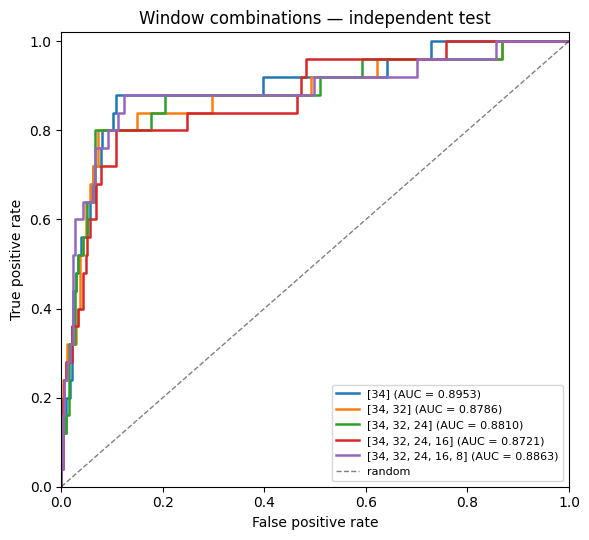

In [5]:
# Block 3 — Experiment B: window combinations (paper Table 3)
combos = [[34], [34, 32], [34, 32, 24], [34, 32, 24, 16], [34, 32, 24, 16, 8]]
cfgs = [dict(label=str(c), features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": c, "filters": 512}) for c in combos]
runner.run_series("B_combo", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("B_combo")))
display(results.fmt(results.table("B_combo", eval_split="cv")))
results.roc("B_combo", title="Window combinations — independent test");

[C_filters 1/5] 128 filters
  seed 42: cv AUC 0.8700 | test AUC 0.8740
[C_filters 2/5] 256 filters
  seed 42: cv AUC 0.8253 | test AUC 0.8711
[C_filters 3/5] 512 filters
  seed 42: cv AUC 0.9011 | test AUC 0.8975
[C_filters 4/5] 1024 filters
  seed 42: cv AUC 0.8251 | test AUC 0.8850
[C_filters 5/5] 2048 filters
  seed 42: cv AUC 0.8642 | test AUC 0.8751


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std,conv_params
0,128 filters,0.56,0.9551,0.9276,0.4811,0.8740,0.4780,0.5185,0.4828,0.8740,NaN,13894144.0
1,256 filters,0.52,0.9551,0.9248,0.4509,0.8711,0.5003,0.4906,0.4643,0.8711,NaN,27788288.0
2,512 filters,0.64,0.9431,0.9220,0.5004,0.8975,0.5150,0.5333,0.4571,0.8975,NaN,55576576.0
3,1024 filters,0.64,0.9341,0.9136,0.4750,0.8850,0.5109,0.5079,0.4211,0.8850,NaN,111153152.0
4,2048 filters,0.76,0.9132,0.9025,0.5035,0.8751,0.4464,0.5205,0.3958,0.8751,NaN,222306304.0
5,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN,NaN


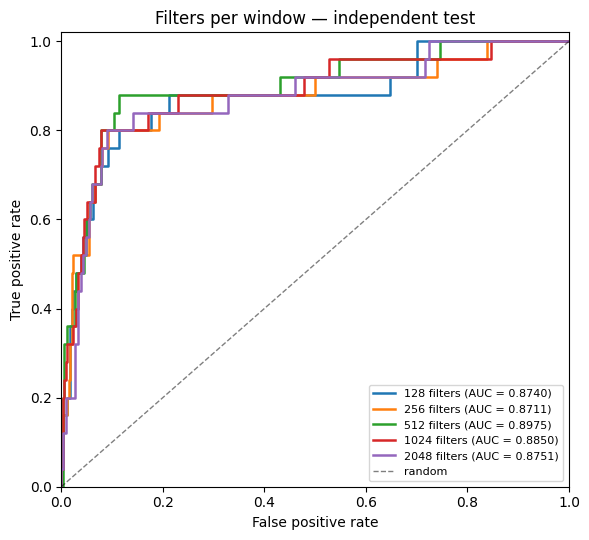

In [6]:
# Block 4 — Experiment C: filters per window (paper Table 4)
# Only the filter count changes: dropout, hidden width and batch size stay at their
# defaults, so differences are due to filters alone. conv_params is in the table on
# purpose: at 2048 filters the convolutions hold ~200-300M parameters for ~1.1k
# training peptides, which is the point of this sweep.
WINDOWS = [34, 32, 24, 16]
cfgs = [dict(label=f"{f} filters", features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": WINDOWS, "filters": f})
        for f in (128, 256, 512, 1024, 2048)]
runner.run_series("C_filters", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("C_filters", extra_cols=("conv_params",))))
results.roc("C_filters", title="Filters per window — independent test");

[J_hidden 1/6] 32 hidden
  seed 42: cv AUC 0.7690 | test AUC 0.8808
[J_hidden 2/6] 64 hidden
  seed 42: cv AUC 0.6966 | test AUC 0.8663
[J_hidden 3/6] 128 hidden
  seed 42: cv AUC 0.8839 | test AUC 0.8735
[J_hidden 4/6] 256 hidden
  seed 42: cv AUC 0.9011 | test AUC 0.8975
[J_hidden 5/6] 512 hidden
  seed 42: cv AUC 0.9059 | test AUC 0.8831
[J_hidden 6/6] 1024 hidden
  seed 42: cv AUC 0.8617 | test AUC 0.8780


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,32 hidden,0.56,0.9521,0.9248,0.4710,0.8808,0.5103,0.5091,0.4667,0.8808,NaN
1,64 hidden,0.36,0.9790,0.9359,0.4182,0.8663,0.4689,0.4390,0.5625,0.8663,NaN
2,128 hidden,0.68,0.9431,0.9248,0.5280,0.8735,0.5080,0.5574,0.4722,0.8735,NaN
3,256 hidden,0.64,0.9431,0.9220,0.5004,0.8975,0.5150,0.5333,0.4571,0.8975,NaN
4,512 hidden,0.72,0.9371,0.9220,0.5375,0.8831,0.5171,0.5625,0.4615,0.8831,NaN
5,1024 hidden,0.68,0.9341,0.9164,0.5023,0.8780,0.4379,0.5312,0.4359,0.8780,NaN
6,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,32 hidden,0.4314,0.9444,0.9079,0.3515,0.7690,0.3323,0.4000,0.3729,0.7690,NaN
1,64 hidden,0.2843,0.9745,0.9254,0.3246,0.6966,0.2250,0.3515,0.4603,0.6966,NaN
2,128 hidden,0.5980,0.9392,0.9149,0.4623,0.8839,0.4055,0.5000,0.4296,0.8839,NaN
3,256 hidden,0.6373,0.9452,0.9233,0.5077,0.9011,0.4277,0.5417,0.4710,0.9011,NaN
4,512 hidden,0.6569,0.9347,0.9149,0.4911,0.9059,0.4360,0.5234,0.4351,0.9059,NaN
5,1024 hidden,0.5686,0.9279,0.9024,0.4122,0.8617,0.3331,0.4531,0.3766,0.8617,NaN
6,all-negative baseline,0.0000,1.0000,0.9289,0.0000,0.5000,0.0711,0.0000,0.0000,NaN,NaN


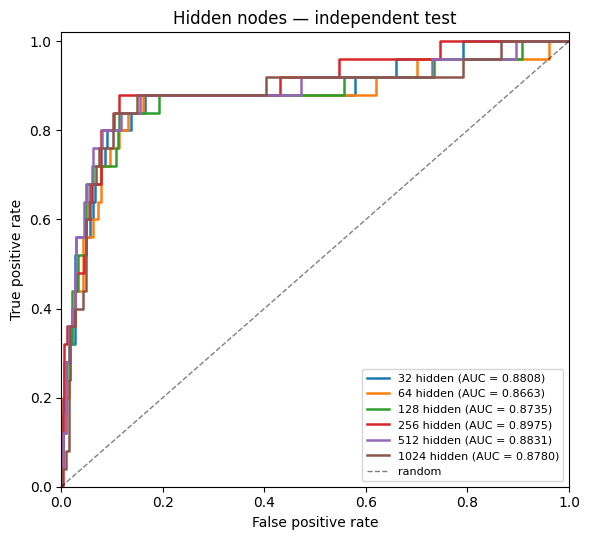

In [7]:
# Block 5 — Experiment J: hidden nodes (width of the fully connected layer)
# Only the hidden width changes; windows, filters and dropout stay at the defaults.
WINDOWS = [34, 32, 24, 16]
cfgs = [dict(label=f"{h} hidden", features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": WINDOWS, "filters": 512, "hidden": h})
        for h in (32, 64, 128, 256, 512, 1024)]
runner.run_series("J_hidden", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("J_hidden")))
display(results.fmt(results.table("J_hidden", eval_split="cv")))
results.roc("J_hidden", title="Hidden nodes — independent test");

[K_dropout 1/5] dropout 0.0
  seed 42: cv AUC 0.8324 | test AUC 0.8920
[K_dropout 2/5] dropout 0.1
  seed 42: cv AUC 0.7950 | test AUC 0.8855
[K_dropout 3/5] dropout 0.3
  seed 42: cv AUC 0.9011 | test AUC 0.8975
[K_dropout 4/5] dropout 0.5
  seed 42: cv AUC 0.8651 | test AUC 0.8826
[K_dropout 5/5] dropout 0.7
  seed 42: cv AUC 0.8364 | test AUC 0.8871


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,dropout 0.0,0.36,0.9820,0.9387,0.4351,0.8920,0.4890,0.4500,0.6000,0.8920,NaN
1,dropout 0.1,0.24,0.9910,0.9387,0.3761,0.8855,0.4805,0.3529,0.6667,0.8855,NaN
2,dropout 0.3,0.64,0.9431,0.9220,0.5004,0.8975,0.5150,0.5333,0.4571,0.8975,NaN
3,dropout 0.5,0.36,0.9701,0.9276,0.3752,0.8826,0.4751,0.4091,0.4737,0.8826,NaN
4,dropout 0.7,0.60,0.9311,0.9081,0.4394,0.8871,0.4856,0.4762,0.3947,0.8871,NaN
5,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,dropout 0.0,0.2843,0.9782,0.9289,0.3426,0.8324,0.3277,0.3625,0.5000,0.8324,NaN
1,dropout 0.1,0.1961,0.9872,0.9310,0.2972,0.7950,0.2787,0.2878,0.5405,0.7950,NaN
2,dropout 0.3,0.6373,0.9452,0.9233,0.5077,0.9011,0.4277,0.5417,0.4710,0.9011,NaN
3,dropout 0.5,0.4314,0.9767,0.9379,0.4712,0.8651,0.3786,0.4972,0.5867,0.8651,NaN
4,dropout 0.7,0.5686,0.9302,0.9045,0.4177,0.8364,0.3547,0.4585,0.3841,0.8364,NaN
5,all-negative baseline,0.0000,1.0000,0.9289,0.0000,0.5000,0.0711,0.0000,0.0000,NaN,NaN


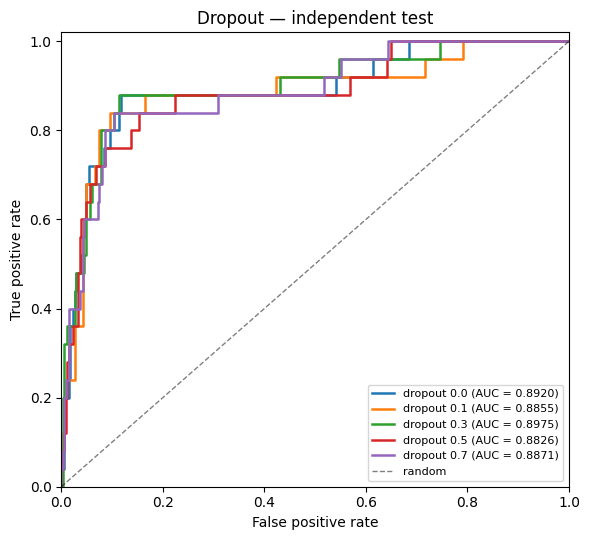

In [8]:
# Block 6 — Experiment K: dropout (applied before and after the hidden layer)
# Only the dropout rate changes. Watch cv vs test: with ~100 training positives, too
# little dropout shows up as a good cv score that does not carry over to test.
WINDOWS = [34, 32, 24, 16]
cfgs = [dict(label=f"dropout {p}", features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": WINDOWS, "filters": 512, "dropout": p})
        for p in (0.0, 0.1, 0.3, 0.5, 0.7)]
runner.run_series("K_dropout", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("K_dropout")))
display(results.fmt(results.table("K_dropout", eval_split="cv")))
results.roc("K_dropout", title="Dropout — independent test");

[D_plm 1/3] ProtTrans
  [skip] ProtTrans — already committed
[D_plm 2/3] ESM-2
  [skip] ESM-2 — already committed
[D_plm 3/3] ESM-1b
  [skip] ESM-1b — already committed
Cross-validation (5 folds)


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,ProtTrans,0.4608,0.9707,0.9344,0.4671,0.8597,0.4427,0.5000,0.5465,0.8597,NaN
1,ESM-2,0.5098,0.9730,0.9400,0.5171,0.8865,0.4946,0.5474,0.5909,0.8865,NaN
2,ESM-1b,0.6569,0.9542,0.9331,0.5509,0.9079,0.4912,0.5826,0.5234,0.9079,NaN
3,all-negative baseline,0.0000,1.0000,0.9289,0.0000,0.5000,0.0711,0.0000,0.0000,NaN,NaN


Independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,ProtTrans,0.40,0.9641,0.9248,0.3864,0.8721,0.4774,0.4255,0.4545,0.8721,NaN
1,ESM-2,0.48,0.9701,0.9359,0.4776,0.8660,0.5589,0.5106,0.5455,0.8660,NaN
2,ESM-1b,0.72,0.9581,0.9415,0.6057,0.8766,0.5625,0.6316,0.5625,0.8766,NaN
3,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


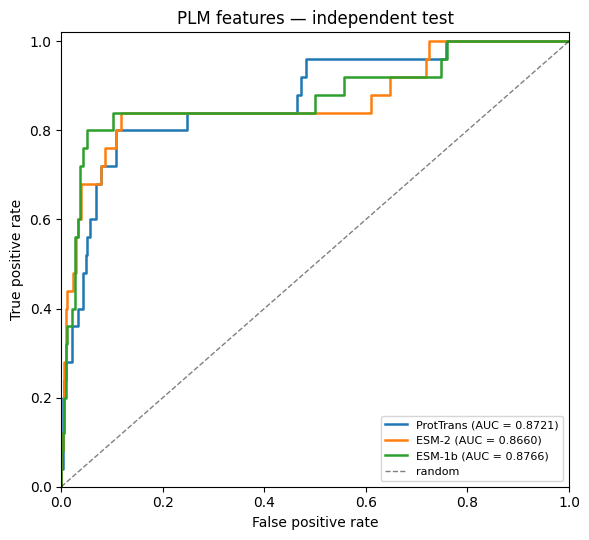

In [9]:
# Block 7 — Experiment D: pre-trained language model features (paper Table 5, Fig 4a)
BEST_WINDOWS, BEST_FILTERS = [34, 32, 24, 16], 512
cfgs = [dict(label=name, features={"kind": "plm", "plm": plm},
             model={"kind": "mcnn", "windows": BEST_WINDOWS, "filters": BEST_FILTERS})
        for plm, name in [("prott5", "ProtTrans"), ("esm2_650m", "ESM-2"), ("esm1b", "ESM-1b")]]
runner.run_series("D_plm", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("Cross-validation (5 folds)")
display(results.fmt(results.table("D_plm", eval_split="cv")))
print("Independent test")
display(results.fmt(results.table("D_plm")))
results.roc("D_plm", title="PLM features — independent test");

[E_clf 1/4] KNN
  [skip] KNN — already committed
[E_clf 2/4] RF
  [skip] RF — already committed
[E_clf 3/4] SVM
  [skip] SVM — already committed
[E_clf 4/4] mCNN
  [skip] mCNN — already committed


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,KNN,0.48,0.7126,0.6964,0.1069,0.6187,0.0963,0.1805,0.1111,0.6187,NaN
1,RF,0.12,0.9671,0.9081,0.1145,0.7134,0.1423,0.1538,0.2143,0.7134,NaN
2,SVM,0.44,0.7605,0.7382,0.1173,0.6910,0.1696,0.1897,0.1209,0.6910,NaN
3,mCNN,0.40,0.9641,0.9248,0.3864,0.8721,0.4774,0.4255,0.4545,0.8721,NaN
4,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


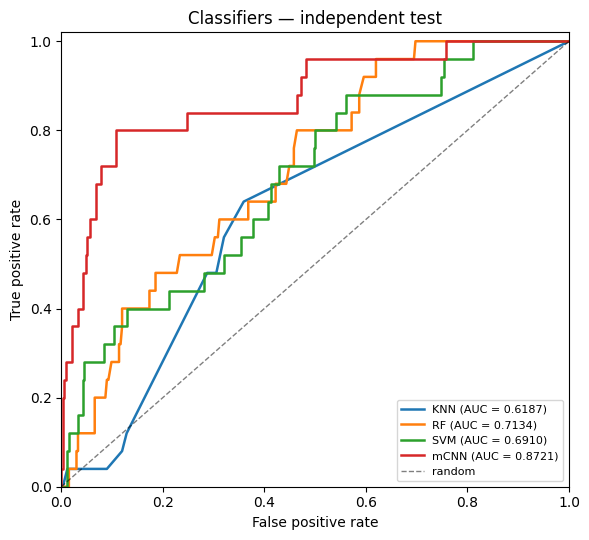

In [10]:
# Block 8 — Experiment E: classifiers (paper Table 6, Fig 4b)
# KNN / RF / SVM take the mean-pooled embedding; the mCNN keeps per-residue input.
cfgs = [dict(label=n.upper(), features={"kind": "plm_pooled", "plm": PLM},
             model={"kind": "sklearn", "name": n}) for n in ("knn", "rf", "svm")]
cfgs.append(dict(label="mCNN", features={"kind": "plm", "plm": PLM},
                 model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 512}))
runner.run_series("E_clf", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("E_clf")))
results.roc("E_clf", title="Classifiers — independent test");

In [11]:
# Block 9 — Experiment F: MHC-I vs MHC-II (paper Table 7)
# No training: this re-scores the best stored run on two subsets of its own predictions.
rid = results.best_run("D_plm")
test = data.add_mhc_class(df[df["split"] == "test"])
subsets = {"Independent test": test["uid"],
           "MHC-I": test.loc[test["mhc"] == "I", "uid"],
           "MHC-II": test.loc[test["mhc"] == "II", "uid"]}
print("best run on CV:", rid)
display(results.fmt(results.breakdown(rid, subsets)))

best run on CV: D_plm__515017c4f3be


,Dataset,n,n_pos,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC
0,Independent test,359,25,0.7200,0.9581,0.9415,0.6057,0.8766,0.5625
1,MHC-I,21,11,0.5455,0.8000,0.6667,0.3553,0.5455,0.6066
2,MHC-II,338,14,0.8571,0.9630,0.9586,0.6363,0.9528,0.6782


In [12]:
# Block 10 — Experiment G: baselines
# Composition alone -> order (one-hot mCNN) -> pretraining (ESM + LogReg) -> local
# scanning on top of pretraining (ESM + CNN, ESM + mCNN). All three ESM rows share the
# same ESM-2 embeddings, so the gaps isolate what pooling, one window and several
# windows add. "length only" is a control: if peptide length alone separates the
# classes, a good AUC from a sequence model proves much less than it appears to.
WINDOWS = [34, 32, 24, 16]
cfgs = [
    dict(label="length only (LogReg)", features={"kind": "length"},
         model={"kind": "sklearn", "name": "logreg"}),
    dict(label="Amino acid + LogReg", features={"kind": "aac"},
         model={"kind": "sklearn", "name": "logreg"}),
    dict(label="One-hot + mCNN", features={"kind": "onehot"},
         model={"kind": "mcnn", "windows": WINDOWS, "filters": 512}),
    dict(label="ESM + LogReg", features={"kind": "plm_pooled", "plm": ESM},
         model={"kind": "sklearn", "name": "logreg"}),
    dict(label="ESM + CNN", features={"kind": "plm", "plm": ESM},
         model={"kind": "mcnn", "windows": [34], "filters": 512}),
    dict(label="ESM + mCNN", features={"kind": "plm", "plm": ESM},
         model={"kind": "mcnn", "windows": WINDOWS, "filters": 512}),
]
runner.run_series("G_baselines", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("G_baselines")))
results.roc("G_baselines", title="Baselines — independent test");

[G_baselines 1/6] length only (LogReg)
  seed 42: cv AUC 0.7547 | test AUC 0.7541
[G_baselines 2/6] Amino acid + LogReg
  seed 42: cv AUC 0.6603 | test AUC 0.6392
[G_baselines 3/6] One-hot + mCNN
  seed 42: cv AUC 0.5776 | test AUC 0.6654
[G_baselines 4/6] ESM + LogReg
  seed 42: cv AUC 0.6819 | test AUC 0.7710
[G_baselines 5/6] ESM + CNN


: 

In [ ]:
# Block 11 — Experiment H: class weighting (CS535 E7)
# At ~1 positive per 13 negatives, this is what moves sensitivity against precision.
base = dict(features={"kind": "plm", "plm": PLM},
            model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 512})
cfgs = [dict(label="weighted BCE", train_cfg={"class_weight": True}, **base),
        dict(label="unweighted BCE", train_cfg={"class_weight": False}, **base)]
runner.run_series("H_weight", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("Tuned threshold (chosen on CV)")
display(results.fmt(results.table("H_weight")))
print("Fixed 0.5 threshold — note how differently 0.5 behaves between the two")
display(results.fmt(results.table("H_weight", thr_mode="fixed")))

[H_weight 1/2] weighted BCE


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8597 | test AUC 0.8721
[H_weight 2/2] unweighted BCE


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8326 | test AUC 0.8952
Tuned threshold (chosen on CV)


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,weighted BCE,0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
1,unweighted BCE,0.44,0.9820,0.9443,0.5058,0.8952,0.5351,0.5238,0.6471,0.8952,0.0
2,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


Fixed 0.5 threshold — note how differently 0.5 behaves between the two


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,weighted BCE,0.24,0.994,0.9415,0.4035,0.8721,0.4774,0.3636,0.75,0.8721,0.0
1,unweighted BCE,0.04,0.997,0.9304,0.1266,0.8952,0.5351,0.0741,0.50,0.8952,0.0
2,all-negative baseline,0.00,1.000,0.9304,0.0000,0.5000,0.0696,0.0000,0.00,NaN,NaN


In [ ]:
# Block 12 — Experiment I: similarity leakage (CS535 E8)
# Random folds let near-duplicate peptides sit on both sides of the split;
# grouped folds keep peptides that share an 8-mer together.
base = dict(features={"kind": "plm", "plm": PLM},
            model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 512})
cfgs = [dict(label="random folds", split_mode="stratified", **base),
        dict(label="similarity-controlled folds", split_mode="grouped", **base)]
runner.run_series("I_leak", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("Cross-validation — the leakage shows up here, not on the test split")
display(results.fmt(results.table("I_leak", eval_split="cv")))
display(results.fmt(results.table("I_leak")))

g = data.kmer_groups(df)
print(f"\n{len(df)} peptides fall into {g.nunique()} shared-8-mer groups; "
      f"largest group has {g.value_counts().iloc[0]}")

[I_leak 1/2] random folds


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8597 | test AUC 0.8721
[I_leak 2/2] similarity-controlled folds


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8241 | test AUC 0.8782
Cross-validation — the leakage shows up here, not on the test split


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,random folds,0.4608,0.9707,0.9344,0.4671,0.8597,0.4427,0.5000,0.5465,0.8597,0.0
1,similarity-controlled folds,0.3431,0.9872,0.9414,0.4543,0.8241,0.4218,0.4545,0.6731,0.8241,0.0
2,all-negative baseline,0.0000,1.0000,0.9289,0.0000,0.5000,0.0711,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,random folds,0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
1,similarity-controlled folds,0.20,0.9910,0.9359,0.3294,0.8782,0.5043,0.3030,0.6250,0.8782,0.0
2,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN



1793 peptides fall into 1788 shared-8-mer groups; largest group has 2


In [ ]:
# Block 13 — report: every table and figure, rebuilt from the store. No training.
# This is what to run after a disconnect to see the whole state of the project.
TITLES = {"G_baselines": "Baselines", "E_clf": "Classifiers", "D_plm": "PLM features",
          "A_window": "Single window sizes", "B_combo": "Window combinations",
          "C_filters": "Filters per window", "J_hidden": "Hidden nodes", "K_dropout": "Dropout",
          "H_weight": "Class weighting", "I_leak": "Similarity leakage"}

for exp_id, title in TITLES.items():
    t = results.table(exp_id)
    if t.empty:
        print(f"--- {title}: not run yet\n")
        continue
    print(f"--- {title} ({exp_id}) — independent test")
    display(results.fmt(t))
    results.roc(exp_id, title=f"{title} — independent test")

runs = results.load_runs()
print(f"\n{len(runs)} committed runs in {config.RESULTS_DIR}")